### Initialization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
DATA = 'A'

### Load data

In [3]:
df_load_12h = pd.read_csv(f'Data/hh_demand_12h_{DATA}.csv')
df_load_1min = pd.read_csv(f'Data/hh_demand_true_{DATA}.csv')
df_weather_12h = pd.read_csv(f'Data/Munich_weather_12h.csv')
df_weather_1min = pd.read_csv(f'Data/Munich_weather_1min.csv')

# Remove Unnamed: 0 column from df_weather_12h and df_weather_1min
df_weather_12h = df_weather_12h.drop(columns=['Unnamed: 0'])

### Preprocess Data

In [4]:
# Add timestamp colum to df_load_12h starting from '2013-01-01 00:00:00' with frequency of 12 hours
df_load_12h['timestamp'] = pd.date_range(start='2013-01-01 00:00:00', periods=len(df_load_12h), freq='12h')
df_load_12h['timestamp'] = pd.to_datetime(df_load_12h['timestamp'])
df_load_12h.set_index('timestamp', inplace=True)

# Add timestamp colum to df_load_1min starting from '2013-01-01 00:00:00' with frequency of 1 minute
df_load_1min['timestamp'] = pd.date_range(start='2013-01-01 00:00:00', periods=len(df_load_1min), freq='1min')
df_load_1min['timestamp'] = pd.to_datetime(df_load_1min['timestamp'])
df_load_1min.set_index('timestamp', inplace=True)

# Add timestamp colum to df_weather_12h starting from '2013-01-01 00:00:00' with frequency of 12 hours
df_weather_12h['timestamp'] = pd.date_range(start='2013-01-01 00:00:00', periods=len(df_weather_12h), freq='12h')
df_weather_12h['timestamp'] = pd.to_datetime(df_weather_12h['timestamp'])
df_weather_12h.set_index('timestamp', inplace=True)

# Rename frst colum to timestamp and set as index in df_weather_1min
df_weather_1min['timestamp'] = df_weather_1min['Unnamed: 0']
df_weather_1min = df_weather_1min.drop(columns=['Unnamed: 0'])
df_weather_1min['timestamp'] = pd.to_datetime(df_weather_1min['timestamp'])
df_weather_1min.set_index('timestamp', inplace=True)

### Plot Load
See if 12h data aligns with resampling 1min data 

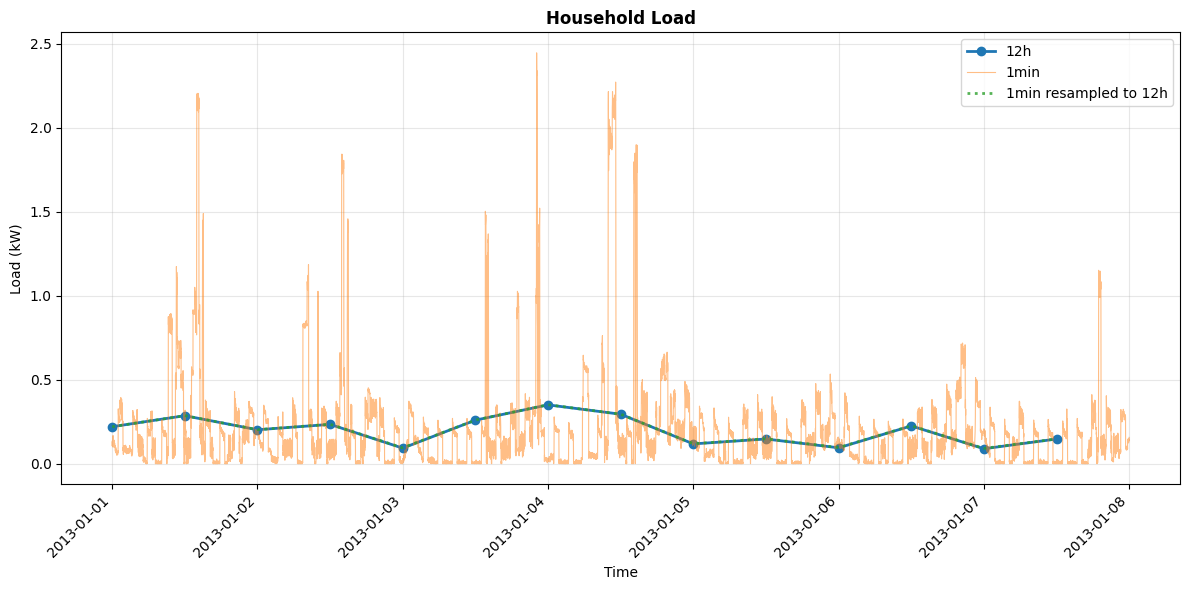

In [5]:
# Only plot first week of January 2013 for both demand datasets
start_date = '2013-01-01 00:00:00'
end_date = '2013-01-07 23:59:00'

# Filter data using .loc[]
df_load_12h_week = df_load_12h.loc[start_date:end_date]
df_load_1min_week = df_load_1min.loc[start_date:end_date]

# Resample 1min load data to 12h frequency by taking the mean
df_load_1min_resampled = df_load_1min_week.resample('12h', label='left').mean()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df_load_12h_week.index, df_load_12h_week['Load'], 
        label='12h', marker='o', linewidth=2)
ax.plot(df_load_1min_week.index, df_load_1min_week['Load'], 
        label='1min', alpha=0.5, linewidth=0.8)
ax.plot(df_load_1min_resampled.index, df_load_1min_resampled['Load'], 
        label='1min resampled to 12h', linestyle=':', linewidth=2, alpha=0.8)

ax.set_title('Household Load', fontweight='bold')
ax.set_ylabel('Load (kW)')
ax.set_xlabel('Time')
ax.legend(loc='best')
ax.grid(True, alpha=0.3)

# Rotate x-axis labels for readability
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()


Jonas: Now we know that the 12h data is just the 1min data resampled to the left. Meaning data from 00:00 to 11:59 is averaged and assigned to 00:00 in the 12h data.

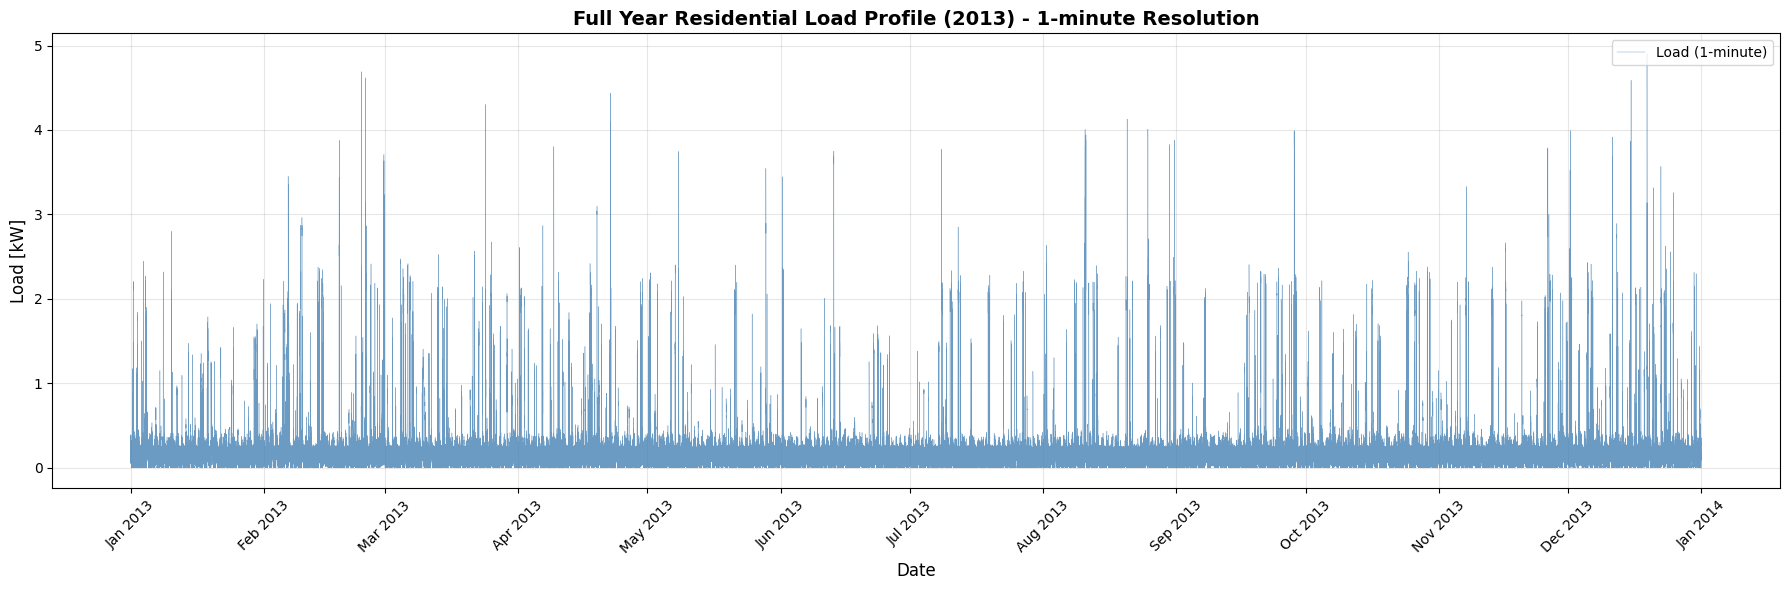

Full Year Load Statistics:
  Mean: 0.1819 kW
  Std Dev: 0.3375 kW
  Min: 0.0000 kW
  Max: 4.8994 kW
  Total points: 525,600


In [7]:
# Plot entire year of 1-minute load data
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(18, 6))

ax.plot(df_load_1min.index, df_load_1min.iloc[:, 0], 
        color='steelblue', linewidth=0.3, alpha=0.8, label='Load (1-minute)')

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Load [kW]', fontsize=12)
ax.set_title('Full Year Residential Load Profile (2013) - 1-minute Resolution', fontsize=14, fontweight='bold')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)

# Format X-axis with month labels
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Print statistics
print("Full Year Load Statistics:")
print(f"  Mean: {df_load_1min.iloc[:, 0].mean():.4f} kW")
print(f"  Std Dev: {df_load_1min.iloc[:, 0].std():.4f} kW")
print(f"  Min: {df_load_1min.iloc[:, 0].min():.4f} kW")
print(f"  Max: {df_load_1min.iloc[:, 0].max():.4f} kW")
print(f"  Total points: {len(df_load_1min):,}")

### Plot weather
Note that the irradiance it the Plane-of-Array irradiance (POA) meaning its the irradiance that directly hits the PV panel, not the straight downwards irradiance. This is assumed from the task description: "This file contains ambient temperature [°C] and solar irradiance [W/m2
] per minute in Munich
for three weeks (winter, spring, summer) for the training and competition stage, created with
Meteonorm1
, assuming a south-facing PV panel tilted by 30°."

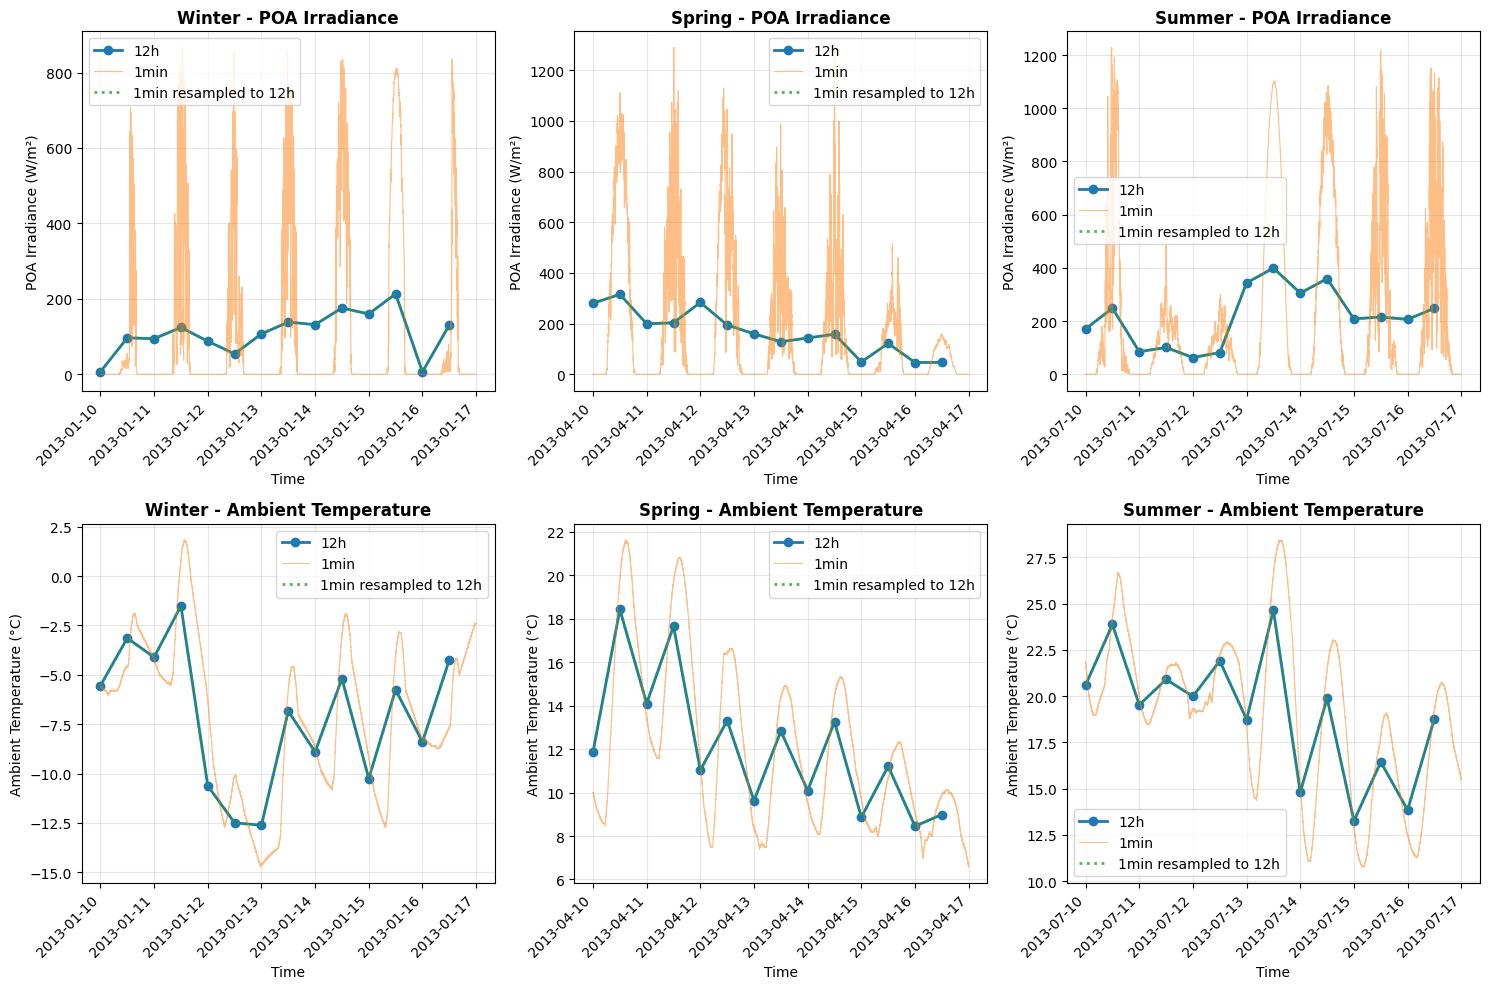

In [6]:
# Define date ranges for three seasons
seasons = [
    {'name': 'Winter', 'start': '2013-01-10 00:00:00', 'end': '2013-01-16 23:59:00'},
    {'name': 'Spring', 'start': '2013-04-10 00:00:00', 'end': '2013-04-16 23:59:00'},
    {'name': 'Summer', 'start': '2013-07-10 00:00:00', 'end': '2013-07-16 23:59:00'}
]

# Variables to plot with their metadata
variables = [
    {'name': 'G_Gk', 'label': 'POA Irradiance', 'unit': 'W/m²'},
    {'name': 'Ta', 'label': 'Ambient Temperature', 'unit': '°C'}
]

fig, axes = plt.subplots(len(variables), len(seasons), figsize=(15, 10))

# Iterate through variables and seasons
for var_idx, var in enumerate(variables):
    for season_idx, season in enumerate(seasons):
        ax = axes[var_idx, season_idx]
        start_date = season['start']
        end_date = season['end']
        
        # Filter data for the season using .loc[] for cleaner indexing
        df_weather_12h_season = df_weather_12h.loc[start_date:end_date]
        df_weather_1min_season = df_weather_1min.loc[start_date:end_date]
        
        # Resample only the season's 1min data to 12h
        df_weather_1min_resampled_season = df_weather_1min_season.resample('12h', label='left').mean()
        
        # Plot data
        ax.plot(df_weather_12h_season.index, df_weather_12h_season[var['name']], 
                label='12h', marker='o', linewidth=2)
        ax.plot(df_weather_1min_season.index, df_weather_1min_season[var['name']], 
                label='1min', alpha=0.5, linewidth=0.8)
        ax.plot(df_weather_1min_resampled_season.index, df_weather_1min_resampled_season[var['name']], 
                label='1min resampled to 12h', linestyle=':', linewidth=2, alpha=0.8)
        
        # Set labels and title
        ax.set_title(f"{season['name']} - {var['label']}", fontweight='bold')
        ax.set_ylabel(f"{var['label']} ({var['unit']})")
        ax.set_xlabel('Time')
        ax.legend(loc='best')
        ax.grid(True, alpha=0.3)
        
        # Rotate x-axis labels for readability
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()


Jonas: 1min weather uses the same resampling as load data